# Ejecuciones y Resultados

<div style="text-align: justify;">

Este _notebook_ ejecuta las variantes del _NSGA-II_ con los hiperparámetros obtenidos en la parametrización (`Results/Parametrizacion`) sobre los datasets de evaluación (`B1`, `B2`, `B3`), usando **31 semillas** derivadas de la fecha del día y compartidas por todas las variantes. Cada ejecución se guarda de forma incremental (CSV de historial + frente F0 en `.npz`), por lo que una sesión interrumpida se reanuda sin repetir lo ya ejecutado.

</div>

In [ ]:
# 1. Clonar el repo
!git clone https://github.com/BenjaminGonzalezH/Thesis.git /content/Thesis

# 2. Montar Drive
from google.colab import drive
drive.mount('/content/drive')

# 3. Copiar las matrices desde Drive al directorio que usa el notebook
import shutil
from pathlib import Path

DRIVE_MATRICES = Path("/content/drive/MyDrive/")                   # <-- ajusta a tu carpeta en Drive
DEST_MATRICES  = Path("/content/Thesis/Datasets/Matrices")        # minúscula: así lo espera el notebook en Colab

DEST_MATRICES.mkdir(parents=True, exist_ok=True)

archivos = list(DRIVE_MATRICES.glob("*.npz"))
for f in archivos:
    shutil.copy2(f, DEST_MATRICES / f.name)

print(f"{len(archivos)} archivos copiados a {DEST_MATRICES}")
print(sorted(p.name for p in DEST_MATRICES.iterdir()))

## 1. Ambiente y semillas

In [ ]:
#######################################################
# MODULO DE PREPARACIÓN DEL AMBIENTE
# Detección de entorno (Colab / Local), rutas del repositorio, respaldo en
# Drive y semillas de las ejecuciones (31, derivadas de la fecha del día).
#######################################################

############################
# Importaciones
############################
import json                                                 # Guardado de las semillas y de las configuraciones.
import sys                                                  # Ajuste de sys.path para importar los módulos de Source Code.
import os                                                   # Llamadas al SO.
import shutil                                               # Copia de archivos entre el disco local y Drive.
from datetime import date                                   # Semilla basada en la fecha del día.
import numpy  as np                                         # Aplicación de operaciones matematicas eficientes.
import pandas as pd                                         # Historial y resumen de resultados.
from pathlib import Path                                    # Aplicar un formato generalizado de direcciones en el script.

############################
# Detección de entorno (Colab / Local)
############################
try:
    import google.colab                                     # Módulo disponible solo dentro de runtimes de Colab.
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    THESIS_DIR = Path("/content/Thesis")
else:
    _cwd = Path(os.getcwd()).resolve()
    THESIS_DIR = next(
        (p for p in (_cwd, *_cwd.parents) if (p / "Datasets").is_dir() and (p / "Source Code").is_dir()),
        None,
    )
    if THESIS_DIR is None:
        raise FileNotFoundError(f"No se encontró la raíz del repositorio (Datasets/ y Source Code/) desde {_cwd}")

MATRICES_DIR = THESIS_DIR / "Datasets" / "Matrices"
print(f"[entorno] {'Colab' if IN_COLAB else 'Local'} → {THESIS_DIR}")

SOURCE_CODE_DIR = THESIS_DIR / "Source Code"
if str(SOURCE_CODE_DIR) not in sys.path:
    sys.path.append(str(SOURCE_CODE_DIR))

############################
# Directorios de resultados y respaldo en Drive
############################
PARAM_DIR   = THESIS_DIR / "Results" / "Parametrizacion"   # Hiperparámetros obtenidos en la parametrización.
RESULTS_DIR = THESIS_DIR / "Results" / "Ejecuciones"       # Resultados de este notebook.
FRENTES_DIR = RESULTS_DIR / "Frentes"                      # Un .npz por ejecución (F0, medoides e historial de HV).
FRENTES_DIR.mkdir(parents=True, exist_ok=True)

DRIVE_RESULTS_DIR = Path("/content/drive/MyDrive/Thesis_Results/Ejecuciones")    # <-- ajusta a tu carpeta en Drive
DRIVE_PARAM_DIR   = Path("/content/drive/MyDrive/Thesis_Results/Parametrizacion")

def _copiar_arbol(origen: Path, destino: Path, restaurar: bool) -> None:
    """Copia recursiva de `origen` a `destino`. Con `restaurar`, no pisa archivos existentes; si no, solo copia lo nuevo o modificado."""
    if not origen.exists():
        return
    for archivo in origen.rglob("*"):
        if not archivo.is_file():
            continue
        objetivo = destino / archivo.relative_to(origen)
        if objetivo.exists() and (restaurar or objetivo.stat().st_mtime >= archivo.stat().st_mtime):
            continue
        objetivo.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(archivo, objetivo)

def sincronizar_drive(restaurar: bool = False) -> None:
    """Local -> Drive (o Drive -> local si `restaurar`). No hace nada fuera de Colab."""
    if not IN_COLAB:
        return
    try:
        if restaurar:
            _copiar_arbol(DRIVE_PARAM_DIR,   PARAM_DIR,   restaurar=True)
            _copiar_arbol(DRIVE_RESULTS_DIR, RESULTS_DIR, restaurar=True)
        else:
            _copiar_arbol(RESULTS_DIR, DRIVE_RESULTS_DIR, restaurar=False)
    except Exception as e:                                  # Un fallo de Drive no debe interrumpir las ejecuciones.
        print(f"[drive] no se pudo {'restaurar' if restaurar else 'respaldar'}: {e}")

sincronizar_drive(restaurar=True)

############################
# Semillas (31, derivadas de la fecha del día AAAAMMDD)
############################
N_SEEDS = 31
SEEDS_FILE = RESULTS_DIR / "seeds_ejecuciones.json"

SEED = int(date.today().strftime("%Y%m%d"))                 # Semilla del día: origen de las 31 semillas.
SEEDS = [int(s) for s in np.random.default_rng(SEED).integers(0, 2**31 - 1, size=N_SEEDS)]

# Persistencia: si ya existen semillas guardadas (sesión previa), se reutilizan para que
# la serie de ejecuciones sea siempre la misma aunque el notebook se reanude otro día.
if SEEDS_FILE.exists():
    with open(SEEDS_FILE, "r", encoding="utf-8") as f:
        _guardado = json.load(f)
    SEED, SEEDS = _guardado["seed"], _guardado["seeds"]
    print(f"[semillas] cargadas desde {SEEDS_FILE.name} (generadas el {_guardado['fecha']})")
else:
    with open(SEEDS_FILE, "w", encoding="utf-8") as f:
        json.dump({"fecha": date.today().isoformat(), "seed": SEED, "seeds": SEEDS}, f, indent=2)
    print(f"[semillas] archivo creado: {SEEDS_FILE.name}")
print(f"[semillas] SEED = {SEED} | {len(SEEDS)} semillas: {SEEDS[:5]} ...")
print(f"[resultados] {RESULTS_DIR}")

## 2. Código fuente e hiperparámetros

In [ ]:
#######################################################
# MODULO DE IMPORTACIÓN DEL CÓDIGO FUENTE E HIPERPARÁMETROS
#######################################################

import solution_encoding                                    # OBJ_FUNCTION_CALLS es un contador global: se reinicia antes de cada ejecución.
from solution_encoding import load_distance_matrix
from LS import build_neighborhood_matrix                    # M_V de MOLS: GE, BI o BOTH.
from nsga2 import run_nsga2
from nsga2_variants import run_nsga2_MOPR, run_nsga2_PLS, run_nsga2_MOLS
from nsga2_variants_bio import run_nsga2_PNS, run_nsga2_DBS

VARIANTES = {
    "NSGA2":       run_nsga2,
    "NSGA2_PLS":   run_nsga2_PLS,
    "NSGA2_MOLS":  run_nsga2_MOLS,
    "NSGA2_DBS":   run_nsga2_DBS,
    "NSGA2_PNS":   run_nsga2_PNS,
    "NSGA2_MOPR":  run_nsga2_MOPR,
}

############################
# Mejores hiperparámetros de la parametrización
############################
def cargar_mejores_parametros() -> dict:
    """
    Lee `mejores_parametros.json`. Si no existe (la parametrización no llegó a escribirlo),
    se reconstruye desde los estudios de Optuna (`<variante>.db`).
    """
    archivo = PARAM_DIR / "mejores_parametros.json"
    if archivo.exists():
        with open(archivo, "r", encoding="utf-8") as f:
            return json.load(f)

    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    mejores = {}
    for variante in VARIANTES:
        db = PARAM_DIR / f"{variante}.db"
        if not db.exists():
            raise FileNotFoundError(f"Sin parámetros para {variante}: falta {archivo.name} y {db.name} en {PARAM_DIR}")
        estudio = optuna.load_study(study_name=variante, storage=f"sqlite:///{db}")
        mejores[variante] = {"hv_f1": estudio.best_value, "parametros": estudio.best_params}
    print(f"[parámetros] reconstruidos desde los estudios .db ({PARAM_DIR})")
    return mejores

MEJORES = cargar_mejores_parametros()
for v in VARIANTES:
    print(f"  {v:<11} HV param = {MEJORES[v]['hv_f1']:.4f} | {MEJORES[v]['parametros']}")

## 3. Cuadro de ejecución

Define qué variantes, datasets y semillas se ejecutan. Los resultados quedan en `Results/Ejecuciones`:

| Archivo | Contenido |
|---|---|
| `historial_ejecuciones.csv` | Registro acumulativo (una fila por ejecución: variante, dataset, semilla, hipervolumen inicial/final, generaciones, llamadas, tiempo, fecha y parámetros). |
| `Frentes/<variante>_<dataset>_<semilla>.npz` | Frente F0 (objetivos y medoides) e historial de hipervolumen de la ejecución. |
| `seeds_ejecuciones.json` | Las 31 semillas usadas. |

Las ejecuciones ya registradas (misma variante, dataset y semilla) se omiten, salvo que `REEJECUTAR = True`; en ese caso se agrega una fila nueva al historial y el resumen usa la más reciente.

In [ ]:
#######################################################
# MODULO DE EJECUCIÓN
# Ejecuta variante × dataset × semilla con los mejores hiperparámetros,
# guardando cada ejecución apenas termina (CSV de historial + .npz del frente).
#######################################################

import io                                                   # Silenciar el log por generación de los algoritmos.
import time                                                 # Tiempo por ejecución.
import contextlib                                           # redirect_stdout.
from datetime import datetime

############################
# Configuración del usuario
############################
VARIANTES_A_EJECUTAR = list(VARIANTES)                      # Subconjunto, p. ej. ["NSGA2", "NSGA2_PNS"].
DATASETS_A_EJECUTAR  = ["B1", "B2", "B3"]                   # Datasets de evaluación (prefijo B).
SEEDS_A_EJECUTAR     = SEEDS                                # Subconjunto, p. ej. SEEDS[:5] para una prueba.
REEJECUTAR           = False                                # True: repite ejecuciones ya registradas (se agrega al historial).

############################
# Constantes del experimento
############################
K                      = 4                                  # Medoides por solución.
MAX_OBJ_FUNCTION_CALLS = 100_000                            # Presupuesto POR ejecución.
HISTORIAL_FILE         = RESULTS_DIR / "historial_ejecuciones.csv"
assert set(VARIANTES_A_EJECUTAR) <= set(VARIANTES), "Variante desconocida en VARIANTES_A_EJECUTAR."

############################
# Datasets (carga bajo demanda: B puede ser muy grande)
############################
_CACHE = {}

def cargar_dataset(nombre: str) -> dict:
    """Carga GE/BI. Los M_V y sus radios se calculan solo cuando una configuración de MOLS los requiere."""
    if nombre not in _CACHE:
        _CACHE.clear()                                      # Un solo dataset en memoria a la vez.
        ge, _ = load_distance_matrix(MATRICES_DIR / f"{nombre}_S_DE.npz")
        bi, _ = load_distance_matrix(MATRICES_DIR / f"{nombre}_S_DB_M.npz")
        _CACHE[nombre] = {"ge": ge, "bi": bi, "n": ge.shape[0], "m_v": {}, "radios": {}}
    return _CACHE[nombre]

def radio_mols(ds: dict, fuente: str, percentil: int) -> tuple:
    """M_V y radio `neighborhood` (percentil de M_V sin diagonal), con memoización por dataset."""
    if fuente not in ds["m_v"]:
        ds["m_v"][fuente] = build_neighborhood_matrix(ds["ge"], ds["bi"], fuente)
    clave = (fuente, percentil)
    if clave not in ds["radios"]:
        m_v = ds["m_v"][fuente]
        ds["radios"][clave] = float(np.percentile(m_v[~np.eye(ds["n"], dtype=bool)], percentil))
    return ds["m_v"][fuente], ds["radios"][clave]

############################
# Argumentos de cada variante (misma traducción que en Parametrización)
############################
def kwargs_variante(variante: str, cfg: dict, ds: dict, seed: int) -> dict:
    kw = dict(
        ge_matrix=ds["ge"], bi_matrix=ds["bi"], n=ds["n"], k=K,
        pop_size=cfg["pop_size"], max_obj_function_calls=MAX_OBJ_FUNCTION_CALLS,
        crossover_prob=cfg["crossover_prob"], mutation_prob=cfg["mutation_prob"],
        seed=seed,
    )
    budget = lambda pct: MAX_OBJ_FUNCTION_CALLS * pct // 100

    if variante == "NSGA2_PLS":
        kw["pls_neighborhood"] = cfg["pls_neighborhood"]
        kw["pls_local_budget"] = budget(cfg["pls_local_budget_pct"])
    elif variante == "NSGA2_MOLS":
        m_v, radio = radio_mols(ds, cfg["M_v"], cfg["neighborhood_pct"])
        kw["mode"]              = cfg["mode"]
        kw["m_v_matrix"]        = m_v
        kw["neighborhood"]      = radio
        kw["mols_local_budget"] = budget(cfg["mols_local_budget_pct"])
    elif variante == "NSGA2_PNS":
        kw["nF"]               = cfg["nF"]
    elif variante == "NSGA2_DBS":
        kw["mode"]             = cfg["mode"]
        kw["p"]                = cfg["p_pct"] / 100
    return kw

############################
# Historial
############################
def leer_historial() -> pd.DataFrame:
    return pd.read_csv(HISTORIAL_FILE) if HISTORIAL_FILE.exists() else pd.DataFrame()

def registrar(fila: dict) -> None:
    pd.DataFrame([fila]).to_csv(HISTORIAL_FILE, mode="a", header=not HISTORIAL_FILE.exists(), index=False)

def ejecutadas() -> set:
    h = leer_historial()
    return set() if h.empty else set(zip(h["variante"], h["dataset"], h["semilla"]))

############################
# Ejecución de una corrida
############################
def ejecutar(variante: str, nombre_ds: str, semilla: int) -> dict:
    cfg = MEJORES[variante]["parametros"]
    ds  = cargar_dataset(nombre_ds)

    solution_encoding.OBJ_FUNCTION_CALLS = 0                # Reinicio obligatorio del presupuesto.
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):         # Se silencia el print por generación.
        res = VARIANTES[variante](**kwargs_variante(variante, cfg, ds, semilla))
    segundos = time.time() - t0

    hv = res["history_hv_f1"]
    f0 = np.asarray(res["fronts"][0])
    np.savez_compressed(
        FRENTES_DIR / f"{variante}_{nombre_ds}_{semilla}.npz",
        objectives=np.asarray(res["objectives"])[f0],
        medoids=np.asarray(res["population"])[f0],
        history_hv_f1=np.asarray(hv, dtype=float),
    )
    fila = {
        "fecha": datetime.now().isoformat(timespec="seconds"),
        "variante": variante, "dataset": nombre_ds, "semilla": semilla,
        "hv_inicial": float(hv[0]), "hv_final": float(hv[-1]),
        "tam_f0": int(len(f0)), "generaciones": int(res["generations_run"]),
        "llamadas": int(solution_encoding.OBJ_FUNCTION_CALLS), "segundos": round(segundos, 1),
        "parametros": json.dumps(cfg, ensure_ascii=False),
    }
    registrar(fila)
    sincronizar_drive()                                     # Respaldo en Drive tras cada ejecución (solo Colab).
    return fila

############################
# Cuadro de ejecución (dataset como bucle externo: evita recargar matrices grandes)
############################
hechas = set() if REEJECUTAR else ejecutadas()
total  = len(VARIANTES_A_EJECUTAR) * len(DATASETS_A_EJECUTAR) * len(SEEDS_A_EJECUTAR)
print(f"[plan] {total} ejecuciones en total | {len(hechas)} ya registradas")

contador = 0
for nombre_ds in DATASETS_A_EJECUTAR:
    for variante in VARIANTES_A_EJECUTAR:
        for semilla in SEEDS_A_EJECUTAR:
            contador += 1
            if (variante, nombre_ds, semilla) in hechas:
                continue
            fila = ejecutar(variante, nombre_ds, semilla)
            print(f"[{contador:>4}/{total}] {variante:<11} {nombre_ds} semilla={semilla:<11} "
                  f"HV F0 = {fila['hv_final']:.4f} | |F0| = {fila['tam_f0']:>3} | {fila['segundos'] / 60:.1f} min")
print("\n[fin] ejecuciones completadas")

## 4. Resultados

Resumen del hipervolumen final de F0 por variante y dataset (usa la ejecución más reciente de cada combinación).

In [ ]:
#######################################################
# MODULO DE RESUMEN DE RESULTADOS
#######################################################

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    resumen = (ultimas.groupby(["dataset", "variante"])
               .agg(n=("hv_final", "size"), hv_media=("hv_final", "mean"), hv_desv=("hv_final", "std"),
                    hv_min=("hv_final", "min"), hv_max=("hv_final", "max"),
                    tam_f0_medio=("tam_f0", "mean"), minutos_medio=("segundos", lambda s: s.mean() / 60))
               .round(4))
    resumen.to_csv(RESULTS_DIR / "resumen_resultados.csv")
    sincronizar_drive()
    display(resumen)

    # Matriz semilla × variante (HV final) por dataset: base para las pruebas estadísticas.
    for nombre_ds, g in ultimas.groupby("dataset"):
        print(f"\n{nombre_ds}: HV final por semilla")
        display(g.pivot(index="semilla", columns="variante", values="hv_final").round(4))

## 5. Boxplots por dataset y prueba de normalidad

Separa las ejecuciones por dataset y variante (las 31 semillas de cada combinación), grafica un boxplot por dataset con las 6 variantes del NSGA-II y verifica si cada conjunto de 31 ejecuciones sigue una distribución normal (test de Shapiro-Wilk, α = 0.05).

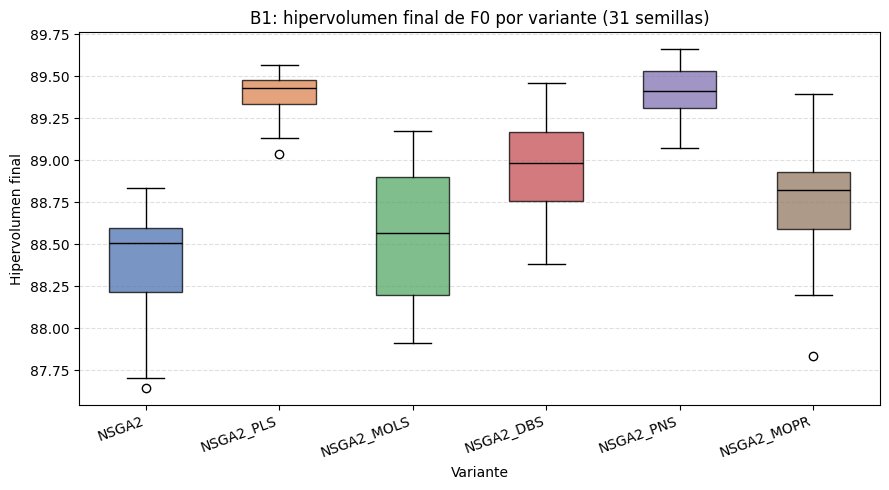

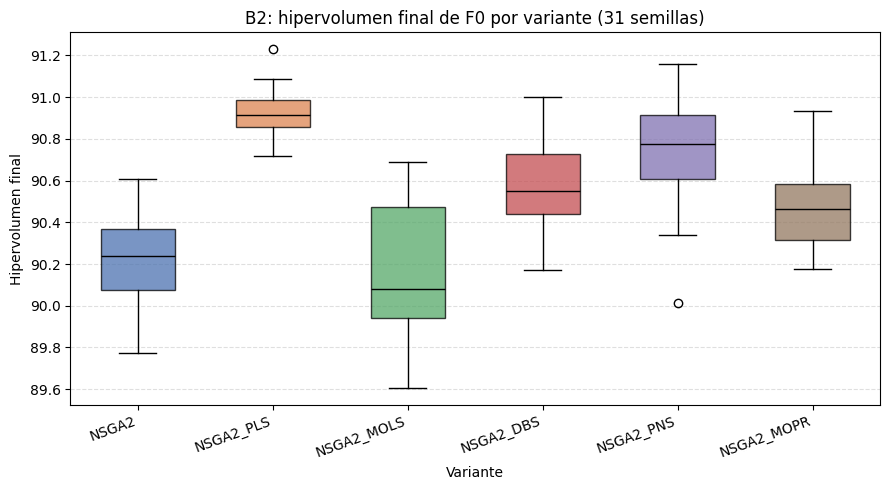

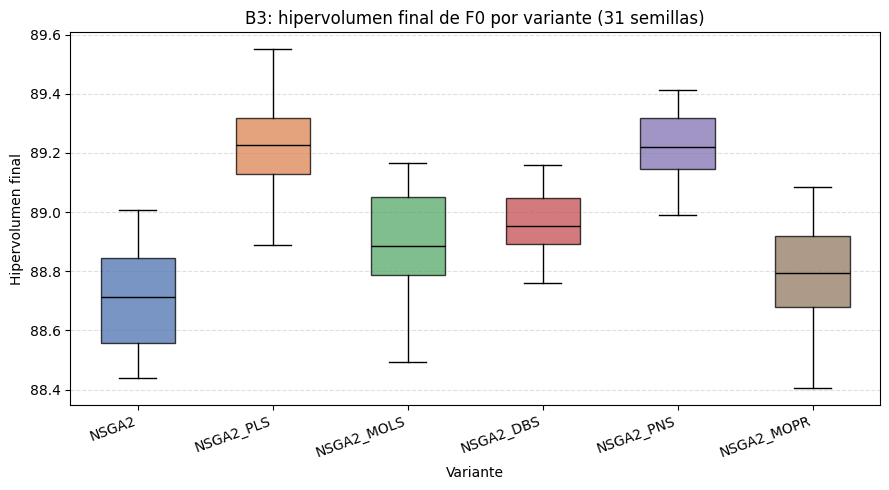

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.8875   0.0036              no
        NSGA2_DBS   31     0.9665   0.4287              sí
        NSGA2_MOLS  31     0.9457   0.1191              sí
        NSGA2_MOPR  31     0.9662   0.4220              sí
        NSGA2_PLS   31     0.9046   0.0094              no
        NSGA2_PNS   31     0.9679   0.4637              sí
B2      NSGA2       31     0.9806   0.8304              sí
        NSGA2_DBS   31     0.9744   0.6457              sí
        NSGA2_MOLS  31     0.9260   0.0341              no
        NSGA2_MOPR  31     0.9465   0.1251              sí
        NSGA2_PLS   31     0.9701   0.5209              sí
        NSGA2_PNS   31     0.9319   0.0494              no
B3      NSGA2       31     0.9407   0.0861              sí
        NSGA2_DBS   31     0.9780   0.7543              sí
        NSGA2_MOLS  31     0.9447   0.1111              sí
        NSGA2_MOPR  31     0.9767   0.7153              sí
        NSGA2_PLS   31     0.9940   0.9997              sí
        NSGA2_PNS   31     0.9699   0.5158              sí


[normalidad] 4 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [12]:
#######################################################
# MODULO DE BOXPLOTS Y NORMALIDAD
# Por dataset: boxplot de las 31 ejecuciones de cada variante y test de
# Shapiro-Wilk por cada conjunto (dataset, variante) de 31 ejecuciones.
#######################################################

import matplotlib.pyplot as plt
from scipy import stats

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    # Orden fijo de variantes y colores categóricos (mismo orden en los 3 boxplots).
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    datasets = sorted(ultimas["dataset"].unique())
    for nombre_ds in datasets:
        datos_ds = ultimas[ultimas["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "hv_final"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: hipervolumen final de F0 por variante (31 semillas)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Hipervolumen final")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    # Test de Shapiro-Wilk por cada combinación dataset x variante (31 ejecuciones).
    filas_normalidad = []
    for (nombre_ds, variante), g in ultimas.groupby(["dataset", "variante"]):
        valores = g["hv_final"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad = (pd.DataFrame(filas_normalidad)
                  .sort_values(["dataset", "variante"])
                  .set_index(["dataset", "variante"]))
    normalidad.to_csv(RESULTS_DIR / "normalidad_shapiro.csv")
    sincronizar_drive()
    display(normalidad)

    n_no_normales = (normalidad["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad] {n_no_normales} de {len(normalidad)} conjuntos (dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05.")

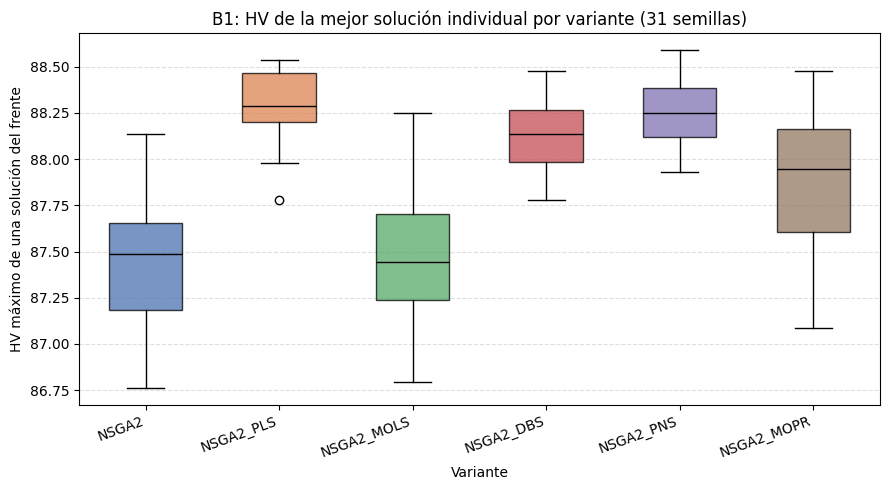

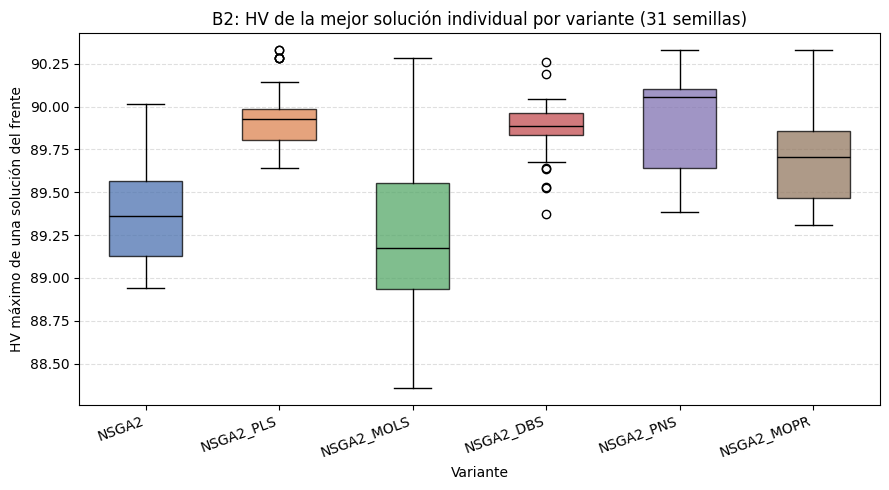

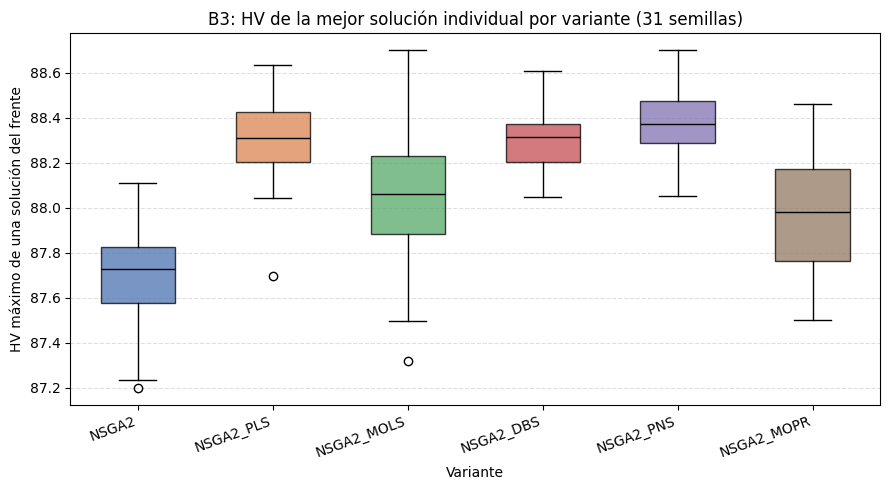

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9772   0.7306              sí
        NSGA2_DBS   31     0.9551   0.2158              sí
        NSGA2_MOLS  31     0.9792   0.7903              sí
        NSGA2_MOPR  31     0.9672   0.4457              sí
        NSGA2_PLS   31     0.9150   0.0174              no
        NSGA2_PNS   31     0.9657   0.4080              sí
B2      NSGA2       31     0.9614   0.3170              sí
        NSGA2_DBS   31     0.9295   0.0426              no
        NSGA2_MOLS  31     0.9740   0.6335              sí
        NSGA2_MOPR  31     0.9523   0.1809              sí
        NSGA2_PLS   31     0.9114   0.0140              no
        NSGA2_PNS   31     0.9003   0.0073              no
B3      NSGA2       31     0.9698   0.5147              sí
        NSGA2_DBS   31     0.9558   0.2256              sí
        NSGA2_MOLS  31     0.9685   0.4778              sí
        NSGA2_MOPR  31     0.9781   0.7590              sí
        NSGA2_PLS   31     0.9497   0.1531              sí
        NSGA2_PNS   31     0.9683   0.4724              sí


[normalidad] 4 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05 (HV de la mejor solución individual).


In [13]:
#######################################################
# MODULO: MEJOR SOLUCIÓN DEL FRENTE (HV INDIVIDUAL MÁXIMO)
# En vez de usar hv_final (HV del frente F0 completo), se lee el .npz de cada
# ejecución, se calcula el HV individual de cada solución del frente (área del
# rectángulo hasta HV_REFERENCE_POINT, sin acumular con las demás) y se toma
# el máximo. Se repite sobre esa métrica el mismo estudio de la sección 5
# (boxplot por dataset + Shapiro-Wilk por dataset × variante).
#######################################################

from performance import HV_REFERENCE_POINT

def hv_individual_maximo(objetivos: np.ndarray, ref_point: tuple = HV_REFERENCE_POINT) -> float:
    """HV de cada solución del frente por separado (sin acumular) y el máximo entre ellas."""
    pts = np.asarray(objetivos, dtype=np.float64).reshape(-1, 2)
    ref_ge, ref_bi = ref_point
    pts = pts[(pts[:, 0] < ref_ge) & (pts[:, 1] < ref_bi)]
    if len(pts) == 0:
        return 0.0
    hv_por_solucion = (ref_ge - pts[:, 0]) * (ref_bi - pts[:, 1])
    return float(hv_por_solucion.max())

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas_mejor = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    filas_mejor_sol = []
    faltantes = []
    for fila in ultimas_mejor.itertuples():
        archivo = FRENTES_DIR / f"{fila.variante}_{fila.dataset}_{fila.semilla}.npz"
        if not archivo.exists():
            faltantes.append(archivo.name)
            continue
        with np.load(archivo) as datos:
            objetivos = datos["objectives"]
        filas_mejor_sol.append({
            "dataset": fila.dataset, "variante": fila.variante, "semilla": fila.semilla,
            "hv_mejor_sol": hv_individual_maximo(objetivos),
        })
    if faltantes:
        print(f"[aviso] {len(faltantes)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): "
              f"{faltantes[:5]}{'...' if len(faltantes) > 5 else ''}")

    mejor_sol = pd.DataFrame(filas_mejor_sol)

    ############################
    # Boxplot por dataset (mismo orden y colores que la sección 5)
    ############################
    datasets_mejor = sorted(mejor_sol["dataset"].unique())
    for nombre_ds in datasets_mejor:
        datos_ds = mejor_sol[mejor_sol["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "hv_mejor_sol"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: HV de la mejor solución individual por variante (31 semillas)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("HV máximo de una solución del frente")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    ############################
    # Shapiro-Wilk por cada combinación dataset x variante
    ############################
    filas_normalidad_mejor = []
    for (nombre_ds, variante), g in mejor_sol.groupby(["dataset", "variante"]):
        valores_grupo = g["hv_mejor_sol"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores_grupo)
        filas_normalidad_mejor.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores_grupo),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_mejor = (pd.DataFrame(filas_normalidad_mejor)
                         .sort_values(["dataset", "variante"])
                         .set_index(["dataset", "variante"]))
    normalidad_mejor.to_csv(RESULTS_DIR / "normalidad_shapiro_mejor_solucion.csv")
    sincronizar_drive()
    display(normalidad_mejor)

    n_no_normales_mejor = (normalidad_mejor["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad] {n_no_normales_mejor} de {len(normalidad_mejor)} conjuntos (dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05 (HV de la mejor solución individual).")

## 6. Prueba no paramétrica (Friedman) y post-hoc

No todos los conjuntos de 31 ejecuciones son normales (sección 5), así que la comparación entre variantes usa pruebas no paramétricas. Las 31 semillas son las mismas para las 6 variantes de cada dataset (diseño pareado/bloqueado), por lo que corresponde el **test de Friedman** (alternativa no paramétrica al ANOVA de medidas repetidas) en lugar de Kruskal-Wallis. Cuando Friedman detecta diferencias globales (α = 0.05), se aplica un post-hoc de **Wilcoxon signed-rank por pares** con corrección de **Holm-Bonferroni** para controlar el error de tipo I por comparaciones múltiples.

In [ ]:
#######################################################
# MODULO DE PRUEBA NO PARAMÉTRICA (FRIEDMAN) Y POST-HOC
# Comparación pareada por semilla entre las 6 variantes de cada dataset: test
# de Friedman y, si hay diferencias globales, post-hoc de Wilcoxon signed-rank
# por pares con corrección de Holm-Bonferroni.
#######################################################

from itertools import combinations
from scipy.stats import friedmanchisquare, wilcoxon

def holm_bonferroni(p_valores: np.ndarray) -> np.ndarray:
    """Corrección de Holm-Bonferroni (step-down) para comparaciones múltiples."""
    orden = np.argsort(p_valores)
    m = len(p_valores)
    ajustados = np.empty(m)
    maximo_previo = 0.0
    for rango, idx in enumerate(orden):
        ajustado = min((m - rango) * p_valores[idx], 1.0)
        maximo_previo = max(maximo_previo, ajustado)
        ajustados[idx] = maximo_previo
    return ajustados

ALPHA = 0.05
resultados_friedman = []
tablas_posthoc = {}

for nombre_ds in datasets:
    tabla = (ultimas[ultimas["dataset"] == nombre_ds]
             .pivot(index="semilla", columns="variante", values="hv_final")[ORDEN_VARIANTES])

    estadistico, p_valor = friedmanchisquare(*[tabla[v].to_numpy() for v in ORDEN_VARIANTES])
    resultados_friedman.append({
        "dataset": nombre_ds, "n_semillas": len(tabla), "chi2": round(float(estadistico), 4),
        "p_valor": round(float(p_valor), 6), "diferencias (α=0.05)": "sí" if p_valor < ALPHA else "no",
    })

    if p_valor >= ALPHA:
        continue                                            # Sin diferencias globales: no se hace post-hoc.

    pares = list(combinations(ORDEN_VARIANTES, 2))
    p_crudos = np.array([
        wilcoxon(tabla[a].to_numpy(), tabla[b].to_numpy()).pvalue for a, b in pares
    ])
    p_holm = holm_bonferroni(p_crudos)

    posthoc = pd.DataFrame({
        "variante_a": [a for a, b in pares], "variante_b": [b for a, b in pares],
        "p_valor": p_crudos.round(6), "p_holm": p_holm.round(6),
        "significativo (α=0.05)": np.where(p_holm < ALPHA, "sí", "no"),
    }).sort_values("p_holm")
    tablas_posthoc[nombre_ds] = posthoc

friedman_df = pd.DataFrame(resultados_friedman).set_index("dataset")
friedman_df.to_csv(RESULTS_DIR / "friedman.csv")
display(friedman_df)

for nombre_ds, posthoc in tablas_posthoc.items():
    print(f"\n{nombre_ds}: post-hoc Wilcoxon pareado (Holm)")
    posthoc.to_csv(RESULTS_DIR / f"posthoc_wilcoxon_{nombre_ds}.csv", index=False)
    display(posthoc)

sincronizar_drive()

## 7. XB_BI del frente: promedio y mejor (boxplots y normalidad)

Tercer estudio: en vez del hipervolumen, se extrae de cada `.npz` el objetivo biológico (`XB_BI`) de las soluciones de F0 y se calculan dos métricas por ejecución: el **XB_BI promedio** del frente y el **mejor (mínimo) XB_BI** del frente. Se repite la misma dinámica de la sección 5 (boxplot por dataset con las 6 variantes + test de Shapiro-Wilk por dataset × variante) sobre ambas métricas.

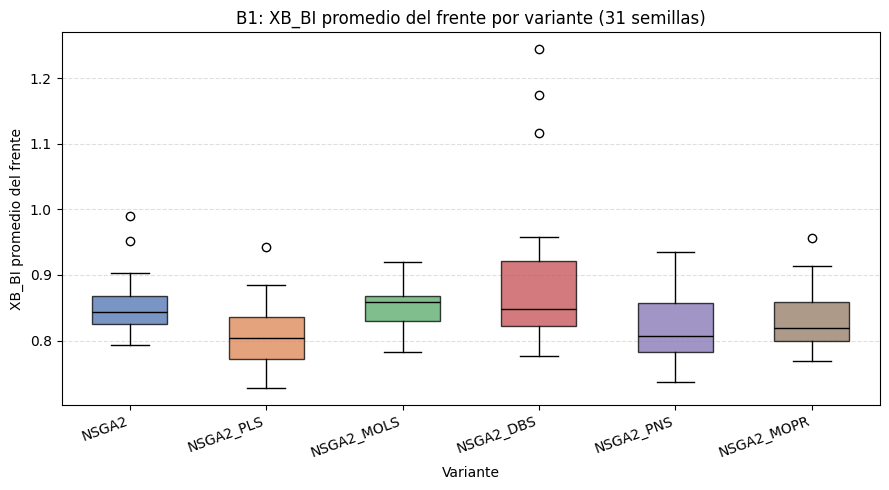

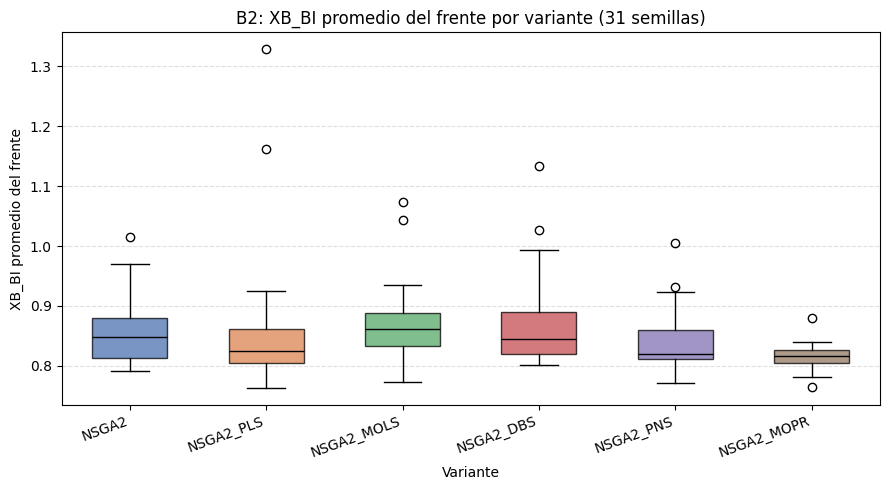

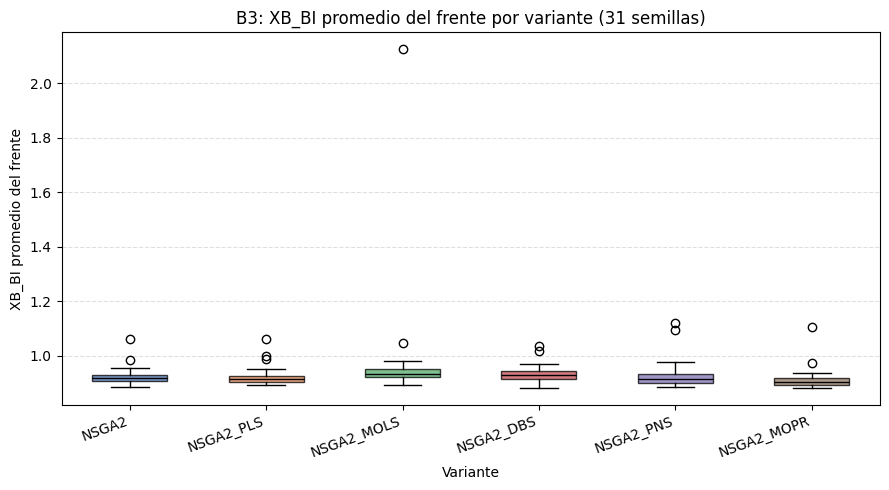

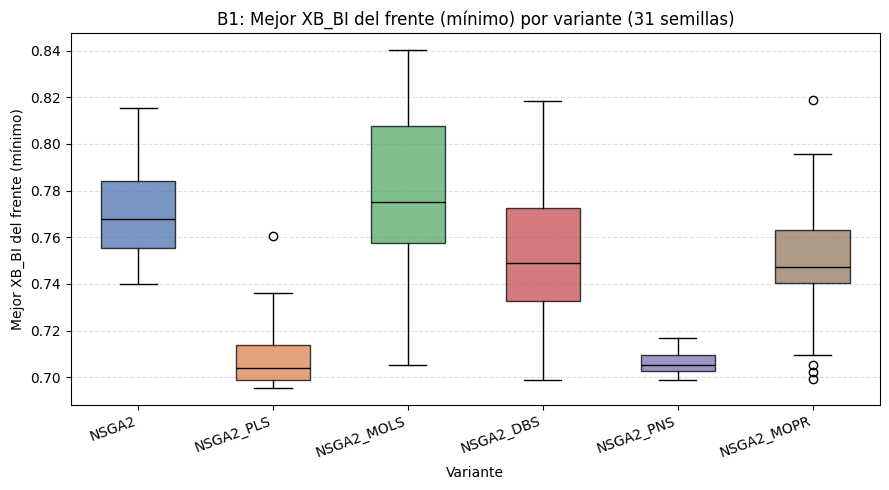

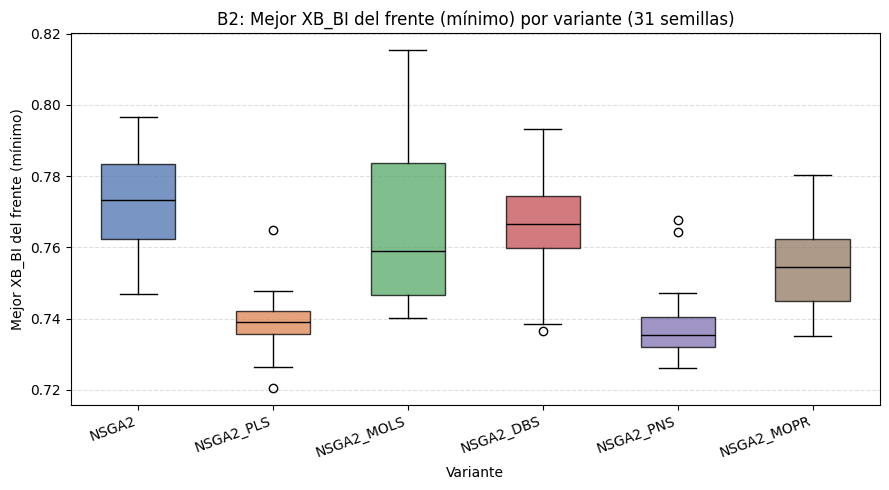

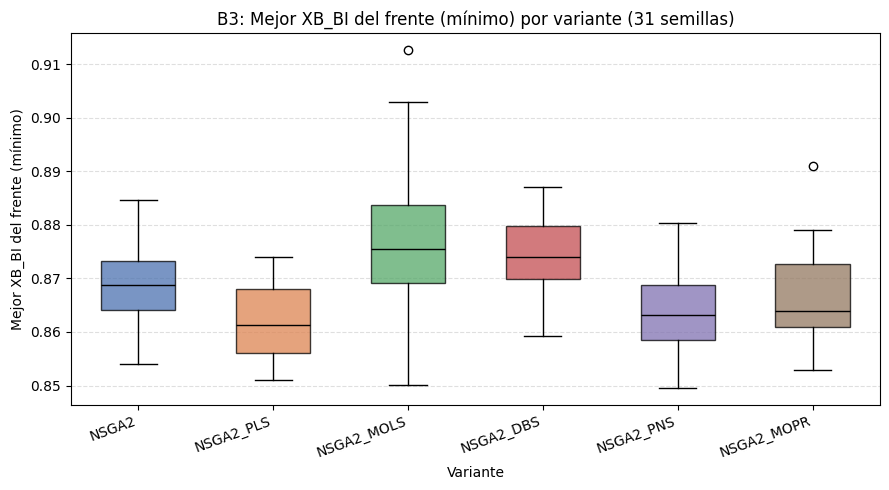

n  shapiro_w  p_valor normal (α=0.05)
metrica        dataset variante                                          
xb_bi_mejor    B1      NSGA2       31     0.9207   0.0246              no
                       NSGA2_DBS   31     0.9622   0.3323              sí
                       NSGA2_MOLS  31     0.9633   0.3568              sí
                       NSGA2_MOPR  31     0.9673   0.4486              sí
                       NSGA2_PLS   31     0.8069   0.0001              no
                       NSGA2_PNS   31     0.9459   0.1203              sí
               B2      NSGA2       31     0.9698   0.5135              sí
                       NSGA2_DBS   31     0.9758   0.6898              sí
                       NSGA2_MOLS  31     0.8940   0.0051              no
                       NSGA2_MOPR  31     0.9515   0.1722              sí
                       NSGA2_PLS   31     0.9141   0.0166              no
                       NSGA2_PNS   31     0.8364   0.0003              no
               B3      NSGA2       31     0.9731   0.6071              sí
                       NSGA2_DBS   31     0.9471   0.1294              sí
                       NSGA2_MOLS  31     0.9729   0.6024              sí
                       NSGA2_MOPR  31     0.9471   0.1297              sí
                       NSGA2_PLS   31     0.9434   0.1026              sí
                       NSGA2_PNS   31     0.9705   0.5317              sí
xb_bi_promedio B1      NSGA2       31     0.8866   0.0034              no
                       NSGA2_DBS   31     0.7599   0.0000              no
                       NSGA2_MOLS  31     0.9807   0.8331              sí
                       NSGA2_MOPR  31     0.9212   0.0255              no
                       NSGA2_PLS   31     0.9568   0.2401              sí
                       NSGA2_PNS   31     0.9365   0.0660              sí
               B2      NSGA2       31     0.8918   0.0045              no
                       NSGA2_DBS   31     0.7836   0.0000              no
                       NSGA2_MOLS  31     0.8850   0.0031              no
                       NSGA2_MOPR  31     0.9462   0.1229              sí
                       NSGA2_PLS   31     0.5936   0.0000              no
                       NSGA2_PNS   31     0.8933   0.0049              no
               B3      NSGA2       31     0.7288   0.0000              no
                       NSGA2_DBS   31     0.8804   0.0024              no
                       NSGA2_MOLS  31     0.2716   0.0000              no
                       NSGA2_MOPR  31     0.5642   0.0000              no
                       NSGA2_PLS   31     0.7118   0.0000              no
                       NSGA2_PNS   31     0.6593   0.0000              no


[normalidad] 19 de 36 conjuntos (métrica × dataset × variante) no superan Shapiro-Wilk con α=0.05 (XB_BI).


In [14]:
#######################################################
# MODULO: XB_BI PROMEDIO Y MEJOR DEL FRENTE
# Por cada ejecución, se extrae del .npz el XB_BI promedio del frente F0 y
# el mejor (mínimo) XB_BI, y se repite el estudio de la sección 5 (boxplot
# por dataset + Shapiro-Wilk por dataset × variante) sobre ambas métricas.
#######################################################

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas_xb_bi = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    filas_xb_bi = []
    faltantes_xb_bi = []
    for fila in ultimas_xb_bi.itertuples():
        archivo = FRENTES_DIR / f"{fila.variante}_{fila.dataset}_{fila.semilla}.npz"
        if not archivo.exists():
            faltantes_xb_bi.append(archivo.name)
            continue
        with np.load(archivo) as datos:
            xb_bi = np.asarray(datos["objectives"], dtype=np.float64)[:, 1]
        xb_bi = xb_bi[np.isfinite(xb_bi)]                   # Excluye soluciones degeneradas (XB_BI = inf).
        if len(xb_bi) == 0:
            continue
        filas_xb_bi.append({
            "dataset": fila.dataset, "variante": fila.variante, "semilla": fila.semilla,
            "xb_bi_promedio": float(xb_bi.mean()), "xb_bi_mejor": float(xb_bi.min()),
        })
    if faltantes_xb_bi:
        print(f"[aviso] {len(faltantes_xb_bi)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): "
              f"{faltantes_xb_bi[:5]}{'...' if len(faltantes_xb_bi) > 5 else ''}")

    xb_bi_df = pd.DataFrame(filas_xb_bi)
    datasets_xb_bi = sorted(xb_bi_df["dataset"].unique())

    METRICAS_XB_BI = {
        "xb_bi_promedio": "XB_BI promedio del frente",
        "xb_bi_mejor":    "Mejor XB_BI del frente (mínimo)",
    }

    ############################
    # Boxplot por dataset y métrica (mismo orden/colores que la sección 5)
    ############################
    for columna, etiqueta in METRICAS_XB_BI.items():
        for nombre_ds in datasets_xb_bi:
            datos_ds = xb_bi_df[xb_bi_df["dataset"] == nombre_ds]
            grupos = [datos_ds.loc[datos_ds["variante"] == v, columna].to_numpy() for v in ORDEN_VARIANTES]
            tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
            if any(n != 31 for n in tamanos.values()):
                print(f"[{nombre_ds}/{columna}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

            fig, ax = plt.subplots(figsize=(9, 5))
            bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
            for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
                patch.set_facecolor(color)
                patch.set_alpha(0.75)
            for mediana in bp["medians"]:
                mediana.set_color("black")
            ax.set_title(f"{nombre_ds}: {etiqueta} por variante (31 semillas)")
            ax.set_xlabel("Variante")
            ax.set_ylabel(etiqueta)
            ax.grid(axis="y", linestyle="--", alpha=0.4)
            plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
            fig.tight_layout()
            plt.show()

    ############################
    # Shapiro-Wilk por cada combinación dataset x variante, para ambas métricas
    ############################
    filas_normalidad_xb_bi = []
    for columna, etiqueta in METRICAS_XB_BI.items():
        for (nombre_ds, variante), g in xb_bi_df.groupby(["dataset", "variante"]):
            valores_grupo = g[columna].to_numpy()
            estadistico, p_valor = stats.shapiro(valores_grupo)
            filas_normalidad_xb_bi.append({
                "metrica": columna, "dataset": nombre_ds, "variante": variante, "n": len(valores_grupo),
                "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
                "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
            })
    normalidad_xb_bi = (pd.DataFrame(filas_normalidad_xb_bi)
                         .sort_values(["metrica", "dataset", "variante"])
                         .set_index(["metrica", "dataset", "variante"]))
    normalidad_xb_bi.to_csv(RESULTS_DIR / "normalidad_shapiro_xb_bi.csv")
    sincronizar_drive()
    display(normalidad_xb_bi)

    n_no_normales_xb_bi = (normalidad_xb_bi["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad] {n_no_normales_xb_bi} de {len(normalidad_xb_bi)} conjuntos (métrica × dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05 (XB_BI).")

In [15]:
#######################################################
# MODULO DE PRUEBA NO PARAMÉTRICA (FRIEDMAN) Y POST-HOC
# SOBRE LA MEJOR SOLUCIÓN INDIVIDUAL (sección 5, mejor_sol/hv_mejor_sol)
# Misma lógica que la sección 6, pero sobre el HV individual máximo del
# frente de cada ejecución en vez de hv_final.
#######################################################

tabla_semillas = (mejor_sol.groupby("dataset")["semilla"]
                   .nunique().to_dict())

resultados_friedman_mejor = []
tablas_posthoc_mejor = {}

for nombre_ds in datasets_mejor:
    tabla = (mejor_sol[mejor_sol["dataset"] == nombre_ds]
             .pivot(index="semilla", columns="variante", values="hv_mejor_sol")
             .dropna()[ORDEN_VARIANTES])                   # Solo semillas con las 6 variantes disponibles.
    if len(tabla) < tabla_semillas[nombre_ds]:
        print(f"[{nombre_ds}] aviso: {tabla_semillas[nombre_ds] - len(tabla)} semilla(s) excluidas de Friedman "
              f"por frentes .npz faltantes en alguna variante (quedan {len(tabla)} pareadas).")

    estadistico, p_valor = friedmanchisquare(*[tabla[v].to_numpy() for v in ORDEN_VARIANTES])
    resultados_friedman_mejor.append({
        "dataset": nombre_ds, "n_semillas": len(tabla), "chi2": round(float(estadistico), 4),
        "p_valor": round(float(p_valor), 6), "diferencias (α=0.05)": "sí" if p_valor < ALPHA else "no",
    })

    if p_valor >= ALPHA:
        continue                                            # Sin diferencias globales: no se hace post-hoc.

    pares = list(combinations(ORDEN_VARIANTES, 2))
    p_crudos = np.array([
        wilcoxon(tabla[a].to_numpy(), tabla[b].to_numpy()).pvalue for a, b in pares
    ])
    p_holm = holm_bonferroni(p_crudos)

    posthoc = pd.DataFrame({
        "variante_a": [a for a, b in pares], "variante_b": [b for a, b in pares],
        "p_valor": p_crudos.round(6), "p_holm": p_holm.round(6),
        "significativo (α=0.05)": np.where(p_holm < ALPHA, "sí", "no"),
    }).sort_values("p_holm")
    tablas_posthoc_mejor[nombre_ds] = posthoc

friedman_mejor_df = pd.DataFrame(resultados_friedman_mejor).set_index("dataset")
friedman_mejor_df.to_csv(RESULTS_DIR / "friedman_mejor_solucion.csv")
display(friedman_mejor_df)

for nombre_ds, posthoc in tablas_posthoc_mejor.items():
    print(f"\n{nombre_ds}: post-hoc Wilcoxon pareado (Holm) — mejor solución individual")
    posthoc.to_csv(RESULTS_DIR / f"posthoc_wilcoxon_mejor_solucion_{nombre_ds}.csv", index=False)
    display(posthoc)

sincronizar_drive()

,n_semillas,chi2,p_valor,diferencias (α=0.05)
dataset,,,,
B1,31,99.6771,0.0,sí
B2,31,61.2304,0.0,sí
B3,31,93.0461,0.0,sí



B1: post-hoc Wilcoxon pareado (Holm) — mejor solución individual


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
0,NSGA2,NSGA2_PLS,0.000000,0.000000,sí
2,NSGA2,NSGA2_DBS,0.000000,0.000000,sí
3,NSGA2,NSGA2_PNS,0.000000,0.000000,sí
5,NSGA2_PLS,NSGA2_MOLS,0.000000,0.000000,sí
10,NSGA2_MOLS,NSGA2_PNS,0.000000,0.000000,sí
9,NSGA2_MOLS,NSGA2_DBS,0.000000,0.000000,sí
4,NSGA2,NSGA2_MOPR,0.000017,0.000157,sí
8,NSGA2_PLS,NSGA2_MOPR,0.000022,0.000173,sí
14,NSGA2_PNS,NSGA2_MOPR,0.000070,0.000489,sí
11,NSGA2_MOLS,NSGA2_MOPR,0.000287,0.001564,sí



B2: post-hoc Wilcoxon pareado (Holm) — mejor solución individual


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
0,NSGA2,NSGA2_PLS,0.000000,0.000000,sí
2,NSGA2,NSGA2_DBS,0.000000,0.000000,sí
3,NSGA2,NSGA2_PNS,0.000000,0.000001,sí
9,NSGA2_MOLS,NSGA2_DBS,0.000000,0.000005,sí
5,NSGA2_PLS,NSGA2_MOLS,0.000001,0.000011,sí
10,NSGA2_MOLS,NSGA2_PNS,0.000003,0.000030,sí
11,NSGA2_MOLS,NSGA2_MOPR,0.000315,0.002831,sí
8,NSGA2_PLS,NSGA2_MOPR,0.000504,0.004034,sí
4,NSGA2,NSGA2_MOPR,0.000831,0.005818,sí
13,NSGA2_DBS,NSGA2_MOPR,0.005086,0.030519,sí



B3: post-hoc Wilcoxon pareado (Holm) — mejor solución individual


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
0,NSGA2,NSGA2_PLS,0.000000,0.000000,sí
2,NSGA2,NSGA2_DBS,0.000000,0.000000,sí
3,NSGA2,NSGA2_PNS,0.000000,0.000000,sí
14,NSGA2_PNS,NSGA2_MOPR,0.000000,0.000002,sí
13,NSGA2_DBS,NSGA2_MOPR,0.000001,0.000011,sí
10,NSGA2_MOLS,NSGA2_PNS,0.000003,0.000035,sí
8,NSGA2_PLS,NSGA2_MOPR,0.000005,0.000042,sí
1,NSGA2,NSGA2_MOLS,0.000008,0.000064,sí
4,NSGA2,NSGA2_MOPR,0.000009,0.000064,sí
5,NSGA2_PLS,NSGA2_MOLS,0.000145,0.000871,sí


## 8. Índice de Jaccard promedio del frente (boxplots y normalidad)

Cuarto estudio: diversidad del frente F0. A partir de los medoides guardados en cada `.npz`, se reconstruyen los labels de clustering (misma matriz GE usada en la ejecución) y se calcula el **índice de Jaccard** entre cada par de soluciones del frente; el promedio de esos pares es la métrica por ejecución. Se repite la misma dinámica de la sección 5 (boxplot por dataset con las 6 variantes + Shapiro-Wilk por dataset × variante).

[load] 'B1_S_DE.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[load] 'B1_S_DB_M.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[load] 'B2_S_DE.npz' → matriz 3024×3024. Primer gen: 'A1BG', último: 'ENSG00000284779'.
[load] 'B2_S_DB_M.npz' → matriz 3024×3024. Primer gen: 'A1BG', último: 'ENSG00000284779'.
[load] 'B3_S_DE.npz' → matriz 10616×10616. Primer gen: 'CDH2', último: 'ENSG00000285994'.
[load] 'B3_S_DB_M.npz' → matriz 10616×10616. Primer gen: 'CDH2', último: 'ENSG00000285994'.


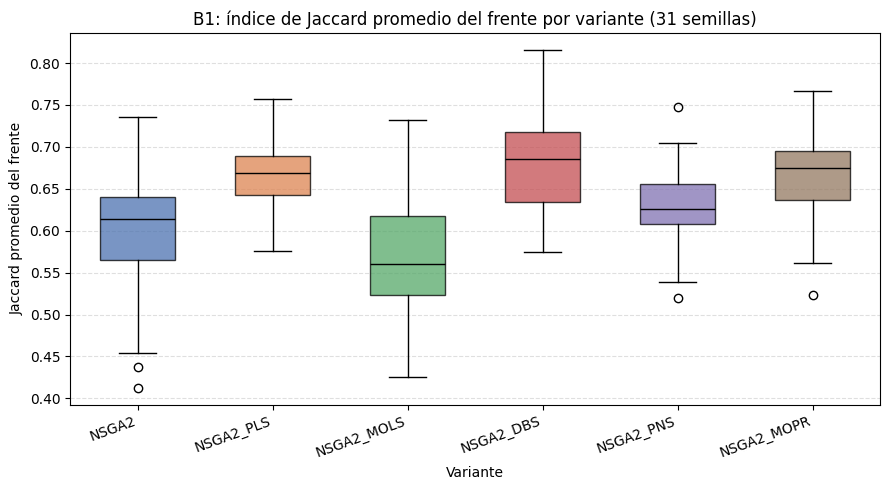

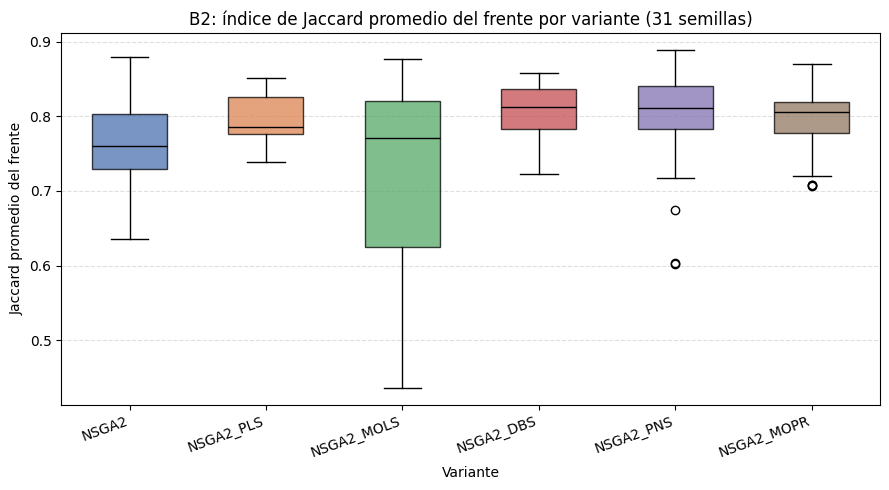

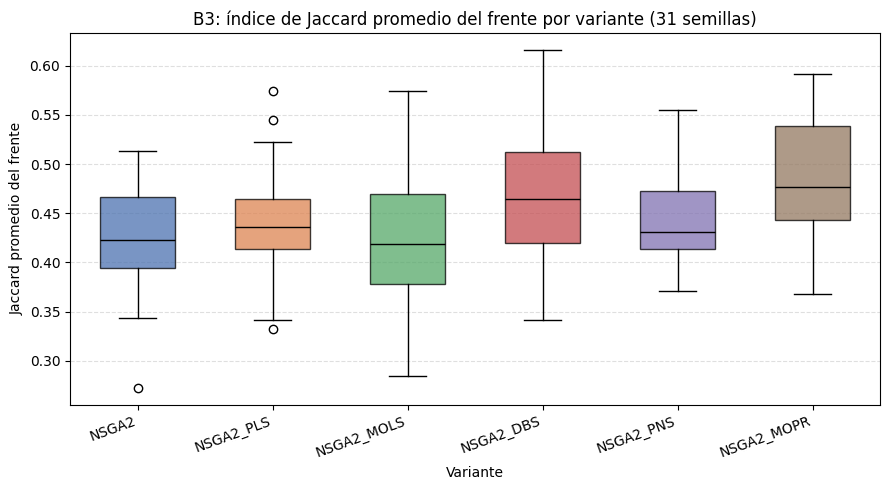

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9286   0.0401              no
        NSGA2_DBS   31     0.9867   0.9581              sí
        NSGA2_MOLS  31     0.9919   0.9970              sí
        NSGA2_MOPR  31     0.9390   0.0775              sí
        NSGA2_PLS   31     0.9742   0.6416              sí
        NSGA2_PNS   31     0.9781   0.7567              sí
B2      NSGA2       31     0.9849   0.9288              sí
        NSGA2_DBS   31     0.9352   0.0609              sí
        NSGA2_MOLS  31     0.9217   0.0262              no
        NSGA2_MOPR  31     0.9269   0.0362              no
        NSGA2_PLS   31     0.9470   0.1286              sí
        NSGA2_PNS   31     0.8662   0.0011              no
B3      NSGA2       31     0.9737   0.6268              sí
        NSGA2_DBS   31     0.9847   0.9247              sí
        NSGA2_MOLS  31     0.9846   0.9240              sí
        NSGA2_MOPR  31     0.9626   0.3407              sí
        NSGA2_PLS   31     0.9695   0.5045              sí
        NSGA2_PNS   31     0.9158   0.0183              no


[normalidad] 5 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05 (Jaccard promedio).


In [17]:
#######################################################
# MODULO: ÍNDICE DE JACCARD PROMEDIO DEL FRENTE
# Por cada ejecución, se reconstruyen los labels de clustering (vía GE) de las
# soluciones del frente F0 a partir de sus medoides, se calcula el índice de
# Jaccard por pares de soluciones y se promedia (diversidad del frente). Se
# repite la dinámica de la sección 5 (boxplot por dataset + Shapiro-Wilk).
#######################################################

from solution_encoding import build_clusters_population
from performance import jaccard_index_solutions

def jaccard_promedio_frente(ge_matrix: np.ndarray, medoids: np.ndarray) -> float:
    """Jaccard promedio entre pares de soluciones del frente (excluye diagonal)."""
    if len(medoids) < 2:
        return np.nan
    labels = build_clusters_population(ge_matrix, medoids)
    J = jaccard_index_solutions(labels)
    iu = np.triu_indices(len(medoids), k=1)
    return float(J[iu].mean())

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas_jaccard = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    filas_jaccard = []
    faltantes_jaccard = []
    for nombre_ds, filas_ds in ultimas_jaccard.groupby("dataset"):
        ge_matrix = cargar_dataset(nombre_ds)["ge"]          # Un dataset (GE/BI) en memoria a la vez.
        for fila in filas_ds.itertuples():
            archivo = FRENTES_DIR / f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz"
            if not archivo.exists():
                faltantes_jaccard.append(archivo.name)
                continue
            with np.load(archivo) as datos:
                medoids = datos["medoids"]
            filas_jaccard.append({
                "dataset": nombre_ds, "variante": fila.variante, "semilla": fila.semilla,
                "jaccard_promedio": jaccard_promedio_frente(ge_matrix, medoids),
            })
    if faltantes_jaccard:
        print(f"[aviso] {len(faltantes_jaccard)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): "
              f"{faltantes_jaccard[:5]}{'...' if len(faltantes_jaccard) > 5 else ''}")

    jaccard_df = pd.DataFrame(filas_jaccard).dropna(subset=["jaccard_promedio"])
    datasets_jaccard = sorted(jaccard_df["dataset"].unique())

    ############################
    # Boxplot por dataset (mismo orden y colores que la sección 5)
    ############################
    for nombre_ds in datasets_jaccard:
        datos_ds = jaccard_df[jaccard_df["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "jaccard_promedio"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: índice de Jaccard promedio del frente por variante (31 semillas)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Jaccard promedio del frente")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    ############################
    # Shapiro-Wilk por cada combinación dataset x variante
    ############################
    filas_normalidad_jaccard = []
    for (nombre_ds, variante), g in jaccard_df.groupby(["dataset", "variante"]):
        valores_grupo = g["jaccard_promedio"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores_grupo)
        filas_normalidad_jaccard.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores_grupo),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_jaccard = (pd.DataFrame(filas_normalidad_jaccard)
                           .sort_values(["dataset", "variante"])
                           .set_index(["dataset", "variante"]))
    normalidad_jaccard.to_csv(RESULTS_DIR / "normalidad_shapiro_jaccard.csv")
    sincronizar_drive()
    display(normalidad_jaccard)

    n_no_normales_jaccard = (normalidad_jaccard["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad] {n_no_normales_jaccard} de {len(normalidad_jaccard)} conjuntos (dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05 (Jaccard promedio).")

### 8.1 Prueba no paramétrica (Friedman) y post-hoc — Jaccard promedio

No todos los conjuntos de la sección 8 son normales, así que se repite la lógica de la sección 6: **Friedman** pareado por semilla sobre `jaccard_promedio`, y si hay diferencias globales (α = 0.05), post-hoc de **Wilcoxon signed-rank por pares** con corrección de **Holm-Bonferroni**.

In [18]:
#######################################################
# MODULO DE PRUEBA NO PARAMÉTRICA (FRIEDMAN) Y POST-HOC
# SOBRE EL JACCARD PROMEDIO DEL FRENTE (sección 8, jaccard_df/jaccard_promedio)
# Misma lógica que la sección 6, pero sobre la diversidad del frente en vez
# de hv_final.
#######################################################

tabla_semillas_jaccard = jaccard_df.groupby("dataset")["semilla"].nunique().to_dict()

resultados_friedman_jaccard = []
tablas_posthoc_jaccard = {}

for nombre_ds in datasets_jaccard:
    tabla = (jaccard_df[jaccard_df["dataset"] == nombre_ds]
             .pivot(index="semilla", columns="variante", values="jaccard_promedio")
             .dropna()[ORDEN_VARIANTES])                   # Solo semillas con las 6 variantes disponibles.
    if len(tabla) < tabla_semillas_jaccard[nombre_ds]:
        print(f"[{nombre_ds}] aviso: {tabla_semillas_jaccard[nombre_ds] - len(tabla)} semilla(s) excluidas de Friedman "
              f"por frentes .npz faltantes en alguna variante (quedan {len(tabla)} pareadas).")

    estadistico, p_valor = friedmanchisquare(*[tabla[v].to_numpy() for v in ORDEN_VARIANTES])
    resultados_friedman_jaccard.append({
        "dataset": nombre_ds, "n_semillas": len(tabla), "chi2": round(float(estadistico), 4),
        "p_valor": round(float(p_valor), 6), "diferencias (α=0.05)": "sí" if p_valor < ALPHA else "no",
    })

    if p_valor >= ALPHA:
        continue                                            # Sin diferencias globales: no se hace post-hoc.

    pares = list(combinations(ORDEN_VARIANTES, 2))
    p_crudos = np.array([
        wilcoxon(tabla[a].to_numpy(), tabla[b].to_numpy()).pvalue for a, b in pares
    ])
    p_holm = holm_bonferroni(p_crudos)

    posthoc = pd.DataFrame({
        "variante_a": [a for a, b in pares], "variante_b": [b for a, b in pares],
        "p_valor": p_crudos.round(6), "p_holm": p_holm.round(6),
        "significativo (α=0.05)": np.where(p_holm < ALPHA, "sí", "no"),
    }).sort_values("p_holm")
    tablas_posthoc_jaccard[nombre_ds] = posthoc

friedman_jaccard_df = pd.DataFrame(resultados_friedman_jaccard).set_index("dataset")
friedman_jaccard_df.to_csv(RESULTS_DIR / "friedman_jaccard.csv")
display(friedman_jaccard_df)

for nombre_ds, posthoc in tablas_posthoc_jaccard.items():
    print(f"\n{nombre_ds}: post-hoc Wilcoxon pareado (Holm) — Jaccard promedio")
    posthoc.to_csv(RESULTS_DIR / f"posthoc_wilcoxon_jaccard_{nombre_ds}.csv", index=False)
    display(posthoc)

sincronizar_drive()

,n_semillas,chi2,p_valor,diferencias (α=0.05)
dataset,,,,
B1,31,52.3456,0.000000,sí
B2,31,21.5438,0.000639,sí
B3,31,13.8018,0.016918,sí



B1: post-hoc Wilcoxon pareado (Holm) — Jaccard promedio


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
9,NSGA2_MOLS,NSGA2_DBS,0.000000,0.000002,sí
5,NSGA2_PLS,NSGA2_MOLS,0.000002,0.000027,sí
11,NSGA2_MOLS,NSGA2_MOPR,0.000017,0.000226,sí
0,NSGA2,NSGA2_PLS,0.000017,0.000226,sí
2,NSGA2,NSGA2_DBS,0.000032,0.000350,sí
10,NSGA2_MOLS,NSGA2_PNS,0.000131,0.001311,sí
12,NSGA2_DBS,NSGA2_PNS,0.000215,0.001938,sí
4,NSGA2,NSGA2_MOPR,0.000414,0.003314,sí
7,NSGA2_PLS,NSGA2_PNS,0.013199,0.092390,no
13,NSGA2_DBS,NSGA2_MOPR,0.024646,0.147874,no



B2: post-hoc Wilcoxon pareado (Holm) — Jaccard promedio


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
9,NSGA2_MOLS,NSGA2_DBS,0.000315,0.004719,sí
2,NSGA2,NSGA2_DBS,0.001065,0.014915,sí
11,NSGA2_MOLS,NSGA2_MOPR,0.003597,0.046763,sí
0,NSGA2,NSGA2_PLS,0.009148,0.109771,no
5,NSGA2_PLS,NSGA2_MOLS,0.009737,0.109771,no
10,NSGA2_MOLS,NSGA2_PNS,0.011014,0.110142,no
4,NSGA2,NSGA2_MOPR,0.030484,0.274360,no
3,NSGA2,NSGA2_PNS,0.041363,0.330907,no
1,NSGA2,NSGA2_MOLS,0.130166,0.911160,no
6,NSGA2_PLS,NSGA2_DBS,0.182076,0.944518,no



B3: post-hoc Wilcoxon pareado (Holm) — Jaccard promedio


,variante_a,variante_b,p_valor,p_holm,significativo (α=0.05)
11,NSGA2_MOLS,NSGA2_MOPR,0.001356,0.020347,sí
4,NSGA2,NSGA2_MOPR,0.003860,0.054039,no
14,NSGA2_PNS,NSGA2_MOPR,0.019775,0.257071,no
2,NSGA2,NSGA2_DBS,0.020909,0.257071,no
8,NSGA2_PLS,NSGA2_MOPR,0.041363,0.454997,no
9,NSGA2_MOLS,NSGA2_DBS,0.050248,0.502483,no
1,NSGA2,NSGA2_MOLS,0.961487,1.000000,no
0,NSGA2,NSGA2_PLS,0.115614,1.000000,no
7,NSGA2_PLS,NSGA2_PNS,1.000000,1.000000,no
6,NSGA2_PLS,NSGA2_DBS,0.125170,1.000000,no
